In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from sklearn.model_selection import train_test_split

In [3]:
DATA_PATH = './dataset/'
x, y = [], []
img_row, img_col = 102, 136
counter = 0
classes = os.listdir(DATA_PATH)
print(classes)

['Boot', 'Sandal', 'Shoe']


In [4]:
for class_path in classes:
    for img_path in os.listdir(f"{DATA_PATH}{class_path}"):
        path = f"{DATA_PATH}{class_path}/{img_path}"
        label = counter
        img = tf.keras.preprocessing.image.load_img(path, target_size=(img_row, img_col))
        img = tf.keras.preprocessing.image.img_to_array(img)
        x.append(img)
        y.append(label)
    counter += 1

x = np.array(x)
y = np.array(y)
x = x.astype('float32') / 255.0

In [6]:
x_train, x_temp, y_train, y_temp = train_test_split(
    x, y, test_size=0.2, random_state=42
)
x_test, x_val, y_test, y_val = train_test_split(
    x_temp, y_temp, test_size=0.5, random_state=42
)

y_train = keras.utils.to_categorical(y_train)
y_test = keras.utils.to_categorical(y_test)
y_val = keras.utils.to_categorical(y_val)
print(x_train.shape)

(1200, 102, 136, 3)


In [25]:
import keras.layers

model = keras.Sequential()

model.add(keras.layers.Conv2D(6, (6,6), activation="relu", input_shape=(img_row, img_col, 3)))
model.add(keras.layers.AveragePooling2D((2, 2), 2))

model.add(keras.layers.Conv2D(16, (6,6), activation="relu"))
model.add(keras.layers.AveragePooling2D((2, 2), 2))

model.add(keras.layers.Flatten())
model.add(keras.layers.Dense(120, activation="relu"))
model.add(keras.layers.Dense(84, activation="relu"))
model.add(keras.layers.Dense(16, activation="relu"))
model.add(keras.layers.Dense(3, activation="softmax"))

model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_8 (Conv2D)               │ (None, 97, 131, 6)     │           654 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_8             │ (None, 48, 65, 6)      │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 43, 60, 16)     │         3,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_9             │ (None, 21, 30, 16)     │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_4 (Flatten)             │ (None, 10080)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 120)            │     1,209,720 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 84)             │        10,164 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 16)             │         1,360 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 3)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,225,421 (4.67 MB)

 Trainable params: 1,225,421 (4.67 MB)

 Non-trainable params: 0 (0.00 B)

In [26]:
model.compile(
    optimizer="adam",
    loss ="categorical_crossentropy",
    metrics=["accuracy"]
)

history = model.fit(
    x_train, y_train,
    epochs=20, batch_size=120,
    validation_data=(x_val, y_val)
)

Epoch 1/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 4s 177ms/step - accuracy: 0.5675 - loss: 0.9650 - val_accuracy: 0.8267 - val_loss: 0.5258
Epoch 2/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 116ms/step - accuracy: 0.8058 - loss: 0.4557 - val_accuracy: 0.8000 - val_loss: 0.4396
Epoch 3/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 129ms/step - accuracy: 0.8717 - loss: 0.3501 - val_accuracy: 0.9000 - val_loss: 0.2601
Epoch 4/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 119ms/step - accuracy: 0.9142 - loss: 0.2588 - val_accuracy: 0.9267 - val_loss: 0.2151
Epoch 5/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 104ms/step - accuracy: 0.9250 - loss: 0.1940 - val_accuracy: 0.9133 - val_loss: 0.2119
Epoch 6/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 113ms/step - accuracy: 0.9300 - loss: 0.1755 - val_accuracy: 0.9333 - val_loss: 0.1800
Epoch 7/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 119ms/step - accuracy: 0.9475 - loss: 0.1545 - val_accuracy: 0.9333 - val_loss: 0.1713
Epoch 8/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 106ms/step - accuracy: 0.9533 - loss: 0.1389 - val_accuracy: 0.

In [27]:
model.evaluate(x_test, y_test)

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.9467 - loss: 0.2327


[0.23274388909339905, 0.9466666579246521]

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step


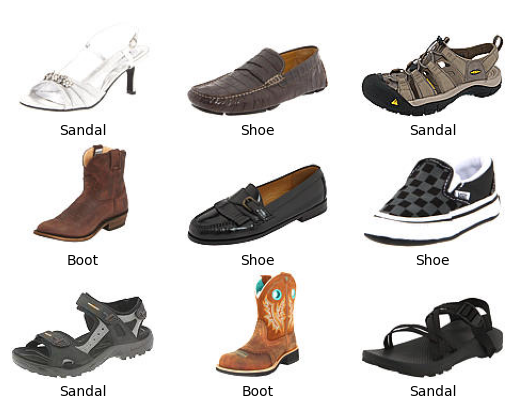

In [28]:
prediction = model.predict(x_test)
predicted_label = np.argmax(prediction, 1)

for i in range(9):
    plt.subplot(3, 3, i+1)
    plt.imshow(x_test[i], cmap='gray')
    plt.axis('off')
    plt.text(
        0.5, -0.15,
        classes[predicted_label[i]], ha='center',
        transform = plt.gca().transAxes
    )

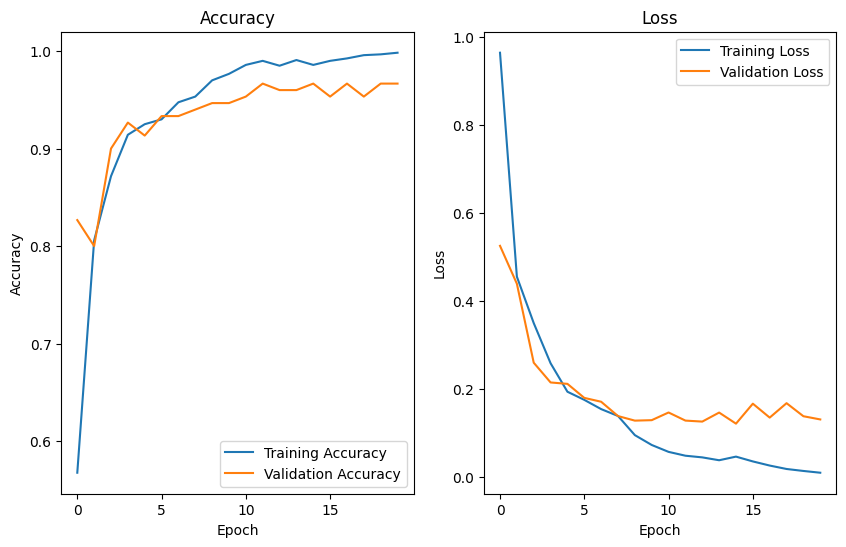

In [29]:
plt.figure(figsize=(10, 6))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title("Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title("Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()


plt.show()